# Sparse microwave fields to a spatial dielectric contrast


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：microwave_dielectric_contrast_imaging

**观测 y：** measurements(1, 9, 10)；illumination_angles(1, 10)；receiver_angles(1, 9)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 二维实介电常数对比度。

**GT/参考来源：** GT为生成观测之前定义的模拟物理目标；须与无噪声观测/拟合预测区分。

**由观测恢复目标：** Lippmann-Schwinger全场积分与散射场采样。本地路径为 `solvers.reconstruct(Born迭代/Tikhonov)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 4（cell编号按文件内从0计）。章节包括：# Sparse microwave fields to a spatial dielectric contrast；### Actual scientific comparisons and historical context；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** GT来自作者模拟物体的2×2格点平均；legacy目标与物理残差须区分。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This active review reconstructs the bound nine-receiver, ten-plane-wave observations through local executable mathematics. These are existing author-simulated observations from EISPY2D, not new synthetic data or real measurements. The unknown is a30×30 real cell-mean contrast chi=(epsilon_r−4)/4 over a0.8m square. Actual truth is an independent area mean of the author’s original60×60 material map; the algorithm never receives it. No display interpolation is used to manufacture extra physical resolution.

Wang and Chew1989, DOI10.1002/ima.1850010111, motivate alternating the linear contrast problem with a new total-field calculation. The independently run reference is the modern EISPY2D implementation, pinned in validation, not the1989 authors’ software. Its author paper is archived as arXiv2111.02185v2(2022); the related2025 IEEE Access DOI is a distinct publication record.

### Physics and conventions

For position r=(x,y), source s and background wavenumber k, the scalar field satisfies E=Ei+k²∫g chi E dA and measured scattered field Es=k²∫g chi E dA at receiver positions. Here Ei=exp(−ik[x cos(phi)+y sin(phi)]) is the known incident wave, g=−i H0^(2)(k distance)/4 is the outgoing2D Green function under exp(+i omega t), and all fields are normalized by unit incident amplitude. Pulse cells use equal-area disk integration, including an analytic self-interaction. The discrete state equation is Et=Ei+GD diag(chi)Et and data equation is Es=GS diag(chi)Et. GS maps the image region to receivers; GD couples image cells. Both are built locally from public geometry, not supplied as fitted target-derived inputs.

## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| measurements | (1, 9, 10) | complex128 | Normalized scalar scattered electric field E_s/E0, dimensionless; axes batch,receiver,illumination; real/imaginary quadratures retained |
| illumination_angles | (1, 10) | float64 | Plane-wave propagation angle in rad, counterclockwise from positive x |
| receiver_angles | (1, 9) | float64 | Receiver polar angle in rad on the stated observation circle, counterclockwise from positive x |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Observation origin | existing author simulation | dimensionless | Reused deposited complex fields rather than a new generated acquisition |
| Frequency | 300000000 | Hz | Single-frequency illumination |
| Background relative permittivity | 4.0 | dimensionless | Known lossless homogeneous medium |
| Background conductivity | 0.0 | S/m | Perfect dielectric approximation |
| Background wavenumber | 12.575070131717595+0i | m^-1 | Deposited numerical calibration; preserve this stored value |
| Background wavelength | 0.4996540966663685 | m | Deposited wavelength convention |
| Incident amplitude | 1.0 | normalized electric-field unit | Phase-calibrated plane waves |
| Time convention | exp(+i omega t) | dimensionless | Outgoing Green function uses Hankel second kind |
| Image region | x and y each[−0.4,+0.4] | m | Finite square support in an unbounded background |
| Output grid | 30 y-cells by30 x-cells | cell | Physical cell means, no artificial display resolution |
| Output cell pitch | 0.8/30 | m | Equal Cartesian cell widths |
| Cell coordinates | half-cell offsets, x and y increasing with array index | m | Row-major flattening, y-cell then x-cell |
| Receiver radius | 1.0 | m | Circular acquisition geometry centered at the origin |
| Receiver count | 9 | receiver | All deposited receiver samples retained |
| Illumination count | 10 | source | All deposited plane-wave experiments retained |
| Angular sampling | np.arange(0,2*pi,2*pi/count) | rad | Stored angle arrays retain original floating-point values |
| Noise level | 1.0 | percent amplitude | Author metadata: random-phase phasor with magnitude1% of each noiseless complex sample, rather than Gaussian component variance |
| Spatial boundary | unbounded homogeneous outgoing-wave medium | dimensionless | No periodic physical boundary or reflecting image border |
| Pulse discretization | equal-area circular cell integration | dimensionless | Cell area dx*dy, equivalent disk radius sqrt(dx*dy/pi), analytic self term |

All angles and observations are supplied directly. Instrument geometry is independent of the unknown target. The existing noise realization is retained; no simulator seed or object-defining information is supplied.

## 3. Physics

With real cell contrast $\chi=(\epsilon_r-4)/4$ and total field $E$, the discrete state and observation equations are

$$
E=E^{\mathrm{inc}}+G_D\operatorname{diag}(\chi)E,\qquad E^{\mathrm{sc}}=G_S\operatorname{diag}(\chi)E.
$$

$G_D$ couples 900 cells inside the 0.8 m square; $G_S$ maps them to nine receivers for ten plane waves. Fields are normalized by unit incident amplitude. Under $\exp(+\mathrm i\omega t)$, the outgoing scalar Green function is $-\mathrm i H_0^{(2)}(kr)/4$. Equal-area disk integration fixes cell self-interaction and dimensions; changing Hankel branch or time sign changes the model.

## 4. Method

### Explicit inverse and numerical validation

At each outer step, stack K[(receiver,source),cell]=GS[receiver,cell]*Et[cell,source] in receiver-major order and solve (KᴴK+alpha I)chi=Kᴴd, with d the complex observed data and no implicit1/M normalization. The initial Et is Ei. The complex linear update is projected through real relative permittivity epsilon_r=4*(Re(chi)+1) for physical propagation; signed ringing is retained, without clipping. A new total field is obtained by the original finite CG-FFT update. Its per-source step numerator uses a common all-source Frobenius denominator and a Polak–Ribière-like direction, as extracted explicitly in src. It is not silently replaced with textbook per-source CG or a domain solver. Initialization is zero internal field, maximum500 inner updates, residual stop1e−8, and15 outer updates. The three positive Tikhonov parameters0.001/0.01/0.1 are all freshly reconstructed above.

The FFT implementation privately uses the equivalent conjugated Hankel-first-kind system, then conjugates back to the public Hankel-second-kind/time convention. Independent dense-matrix/FFT and complex-adjoint tests verify that convention, together with zero contrast, weak scattering, plane-wave sign and quadratic stationarity. Frozen original geometry, Green matrices, three internal updates, all15 contrast/field stages and complete native output provide separate upstream parity evidence.

Two diagnostics are deliberately separated. The upstream legacy objective evaluates its complex linear chi after a real-permittivity field update. The physical residual evaluates only the submitted real chi and its corresponding physical total field. The standalone Judge independently solves that real-contrast state equation densely; it does not import the solver or use the complex diagnostic as evidence of physical agreement.

## 5. Results




In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json,os,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.visualization import run_experiments,make_figures,export,ncc,nrmse
data=load_data(root/'data/raw_data.npz')
with np.load(root/'evaluation/ground_truth.npz',allow_pickle=False) as f:truth=f['reconstruction'][0].copy()
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f:upstream=f['reconstruction'][0].copy()
with np.load(root/'notebooks/reference_outputs/historical_author_results.npz',allow_pickle=False) as f:historical={k:f[k].copy() for k in f.files}
start=time.perf_counter()
experiments=run_experiments(data,truth,upstream,historical)
print('Actual complete comparison runtime (s):',time.perf_counter()-start)
print(json.dumps(experiments['metrics'],indent=2))
print('Fresh columns: alpha, NCC, dynamic-range NRMSE, physical residual, runtime(s)')
print(experiments['table'])

Fresh alpha 0.001 completed in 66.157 s; physical residual 0.023201646086564425


Fresh alpha 0.01 completed in 65.186 s; physical residual 0.148486859437215


Fresh alpha 0.1 completed in 64.646 s; physical residual 0.5503281012110363


Actual complete comparison runtime (s): 195.9937873000017
{
  "nominal_ncc": 0.8953621762338124,
  "nominal_nrmse": 0.09552068704215007,
  "physical_observation_residual": 0.023201646086564425,
  "final_state_residual": 9.47384030928378e-09,
  "max_difference_from_original": 7.156658390905513e-10,
  "first_born_ncc": 0.8072205902810606,
  "first_born_nrmse": 0.1345711175610445
}
Fresh columns: alpha, NCC, dynamic-range NRMSE, physical residual, runtime(s)
[[1.00000000e-03 8.95362176e-01 9.55206870e-02 2.32016461e-02
  6.61565147e+01]
 [1.00000000e-02 8.87472023e-01 1.04158064e-01 1.48486859e-01
  6.51855459e+01]
 [1.00000000e-01 8.19485803e-01 1.59560699e-01 5.50328101e-01
  6.46458575e+01]]


In [2]:
# Evaluate the fresh standard reconstruction, not an archived reference.
(root/'output').mkdir(exist_ok=True)
prediction_path=Path(os.environ.get('IMAGING_REVIEW_PREDICTION',str(root/'output/reconstruction.npz')))
np.savez_compressed(prediction_path,reconstruction=experiments['results'][0][None].astype('float64'))
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(prediction_path)
assert code==0,report
Path(os.environ.get('IMAGING_REVIEW_REPORT',str(root/'output/judge_report.json'))).write_text(json.dumps(report,indent=2),encoding='utf8')
print(json.dumps(report,indent=2))
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_metrics.npz',**{k:np.asarray(v) for k,v in experiments['metrics'].items()},parameter_table=experiments['table'])
with np.load(root/'notebooks/reference_outputs/cleaned_metrics.npz',allow_pickle=False) as recorded:
    print('Separately archived fresh scalar/table measurements:',recorded.files)

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.8953621762338124,
    "nrmse": 0.09552068704215007,
    "observation_residual": 0.023201636171553772
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.8058259586085068
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.10507275574925905
    },
    "observation_residual": {
      "comparison": "<=",
      "boundary": 0.0255218106788596
    }
  },
  "errors": []
}
Separately archived fresh scalar/table measurements: ['nominal_ncc', 'nominal_nrmse', 'physical_observation_residual', 'final_state_residual', 'max_difference_from_original', 'first_born_ncc', 'first_born_nrmse', 'parameter_table']


### Actual scientific comparisons and historical context

The five groups display measured amplitude/phase and geometry; actual30-cell truth, fresh first-Born and three fresh15-step reconstructions; legacy versus physical residuals, internal work and actual-truth metrics; complex internal fields and physical predictions; and explicitly historical author DE/PSO/GA context. All field and image comparisons use matching units and shared relevant color scales. There is no fitted amplitude, global phase, translation, crop or truth mask.

The supplied upstream case-study notebook discusses DE, PSO and GA in three groups of30 runs. Those deposited stochastic results are retained here solely as cached, unreproduced historical context: their native60 display and author relative-permittivity percent-error metric differ from this fresh30-cell BIM experiment. The selected median-ranked author maps and historical boxplots are labeled accordingly. They are not presented as new executions, substitutes for BIM, or comparable fresh NCC/NRMSE bars. This task selects deterministic BIM scope rather than claiming to reproduce the entire stochastic study.


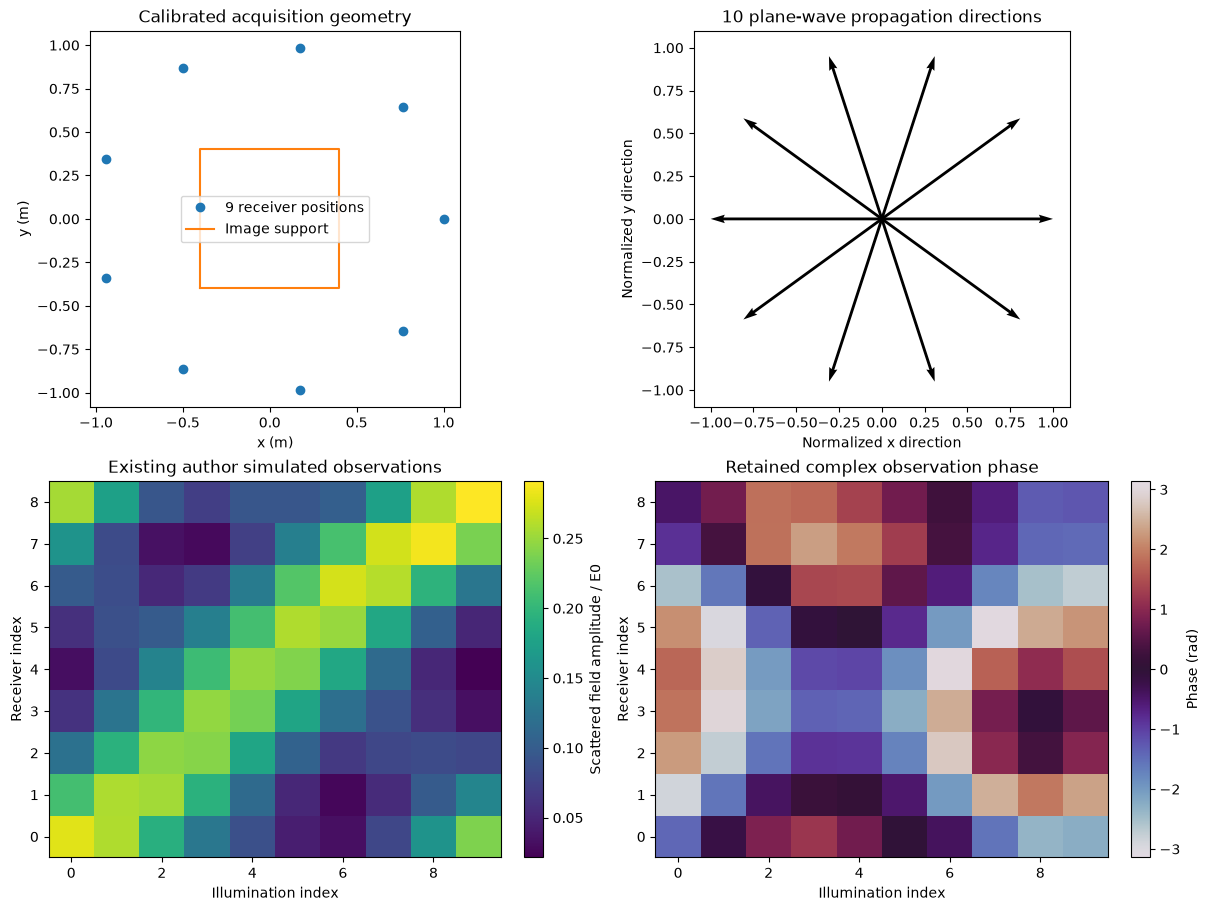

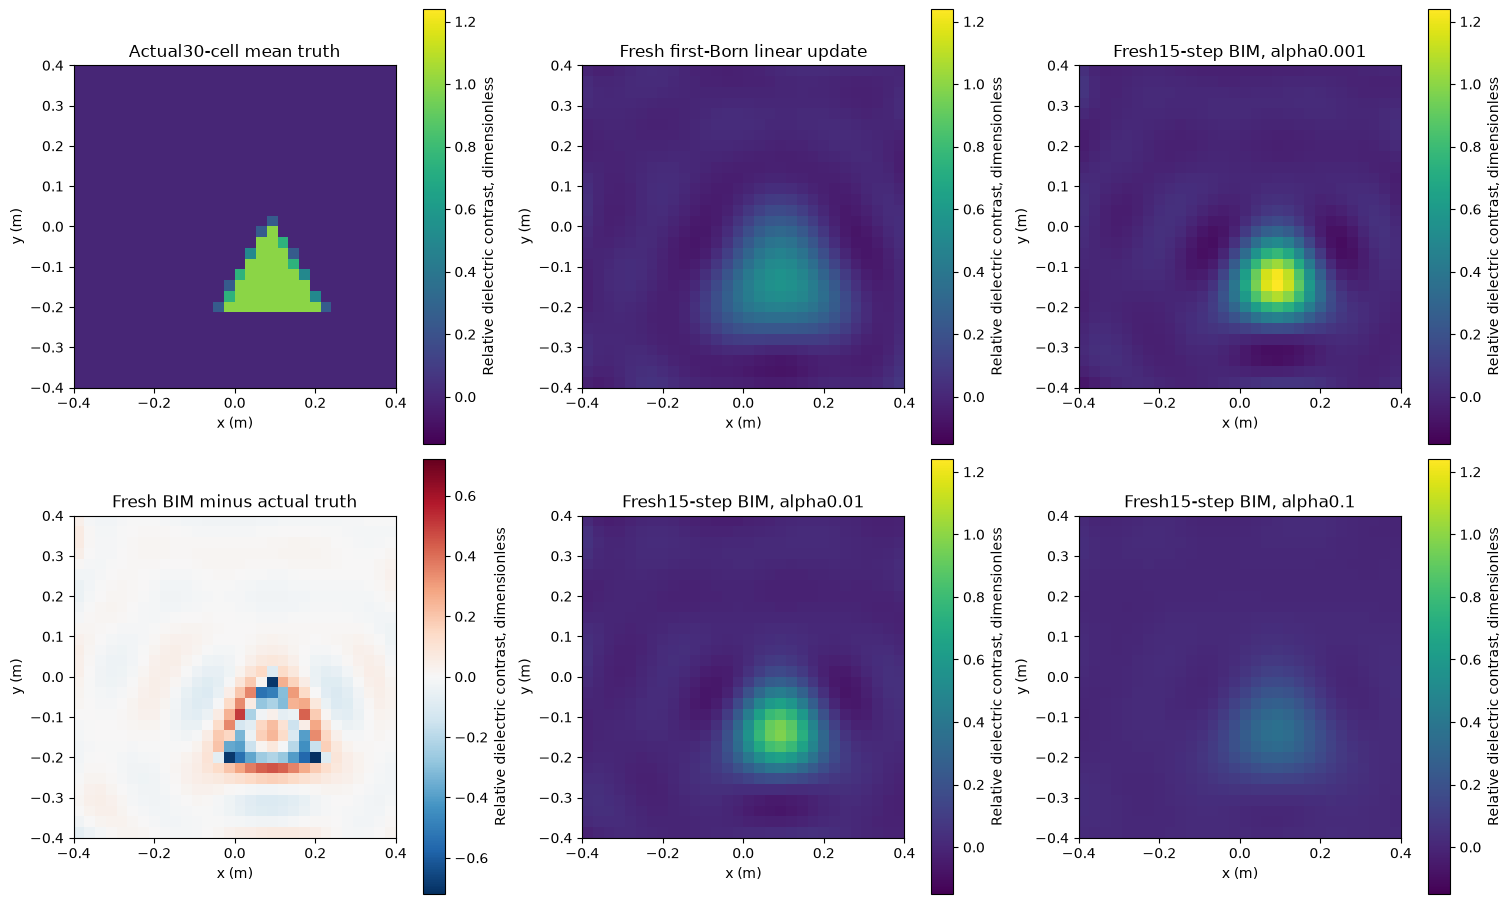

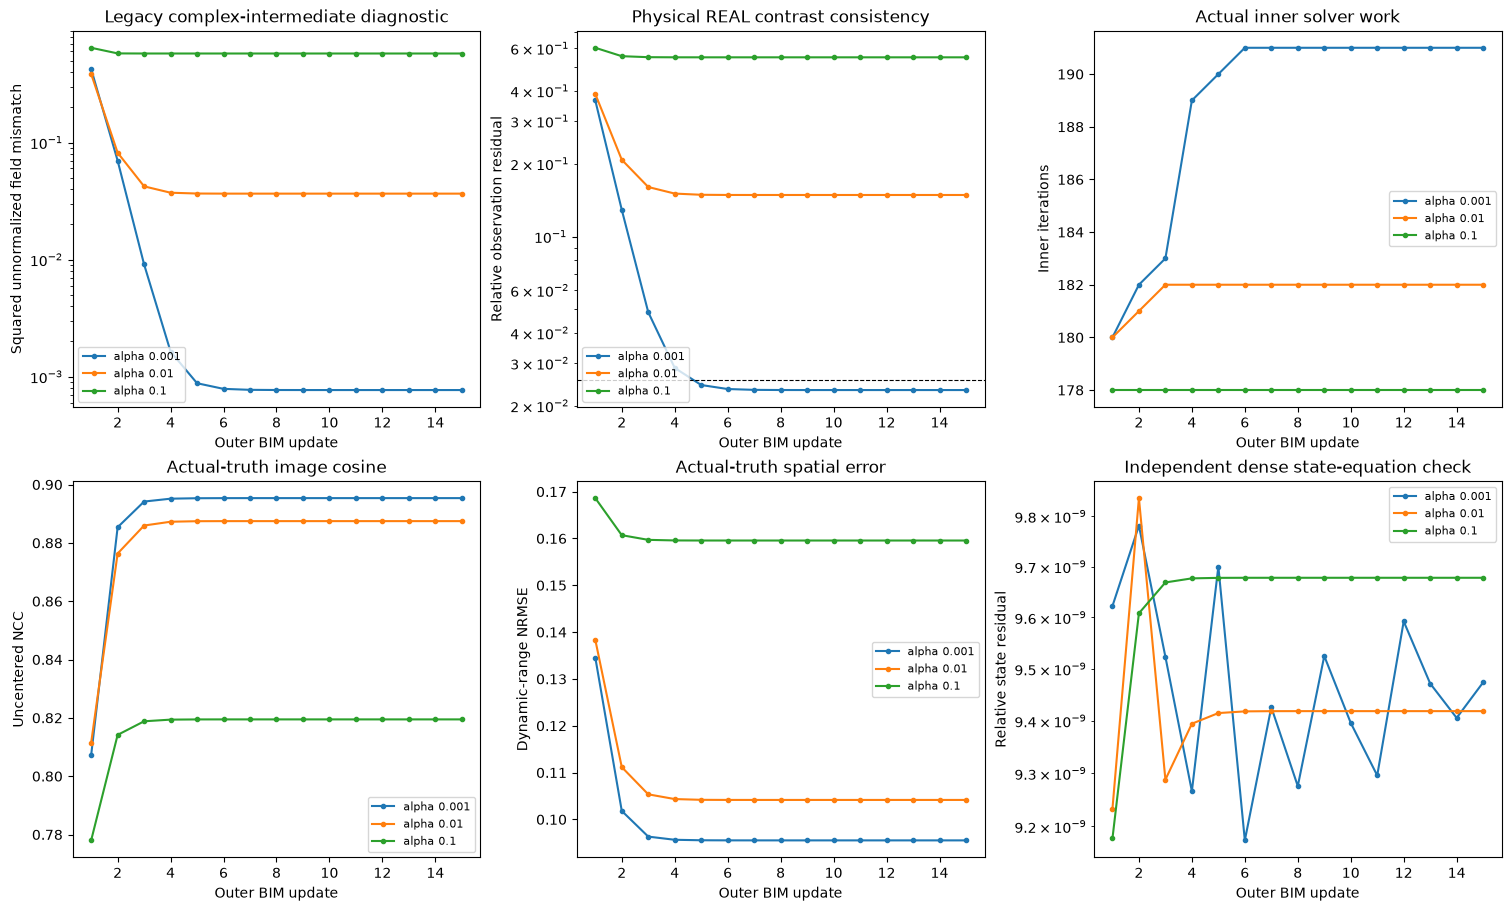

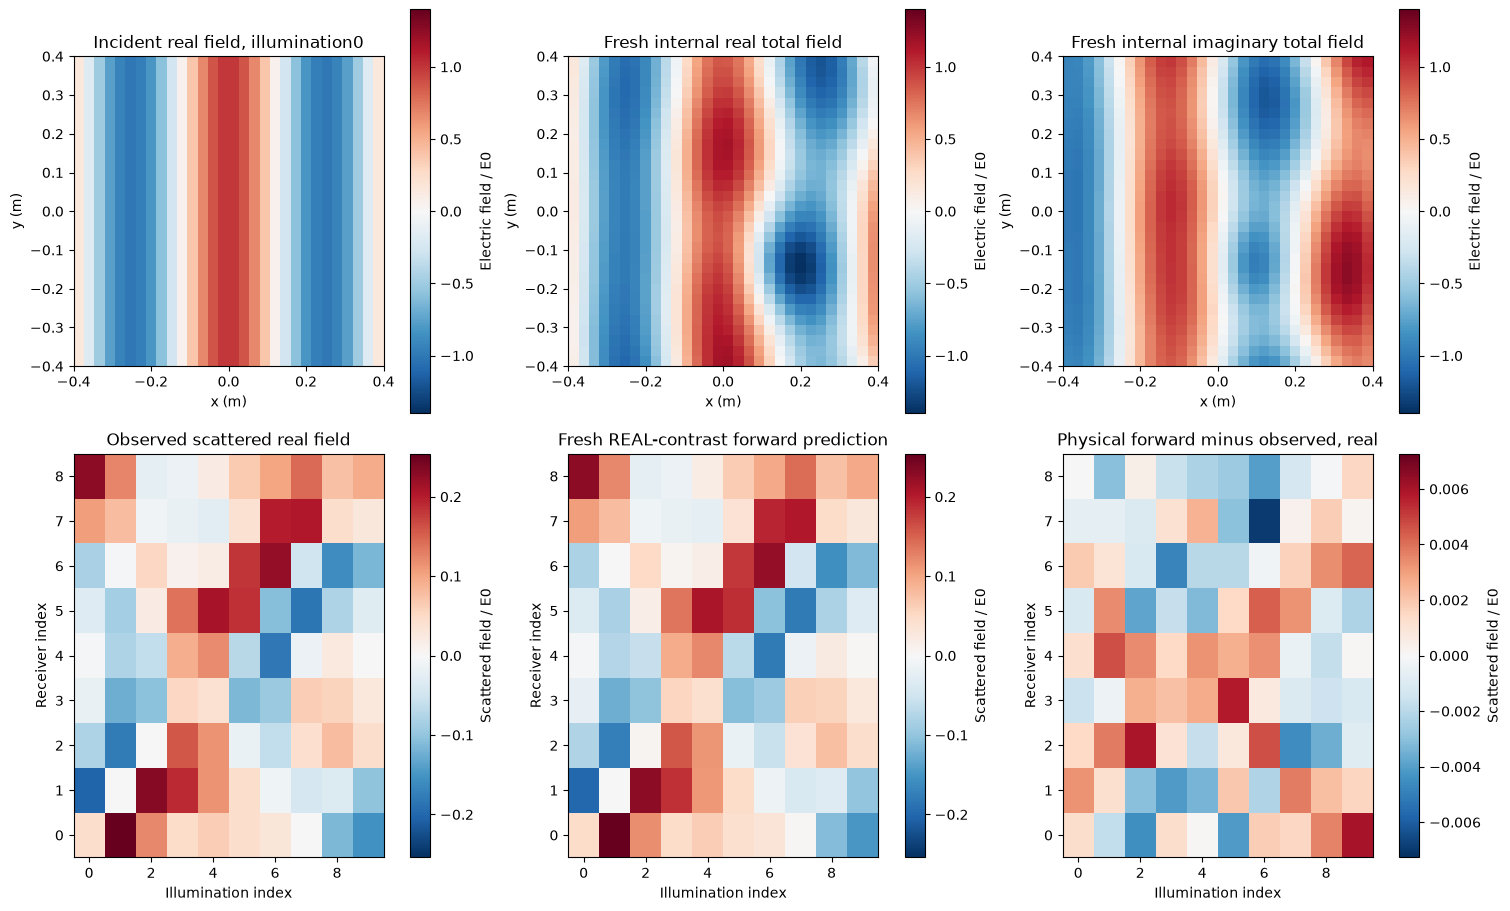

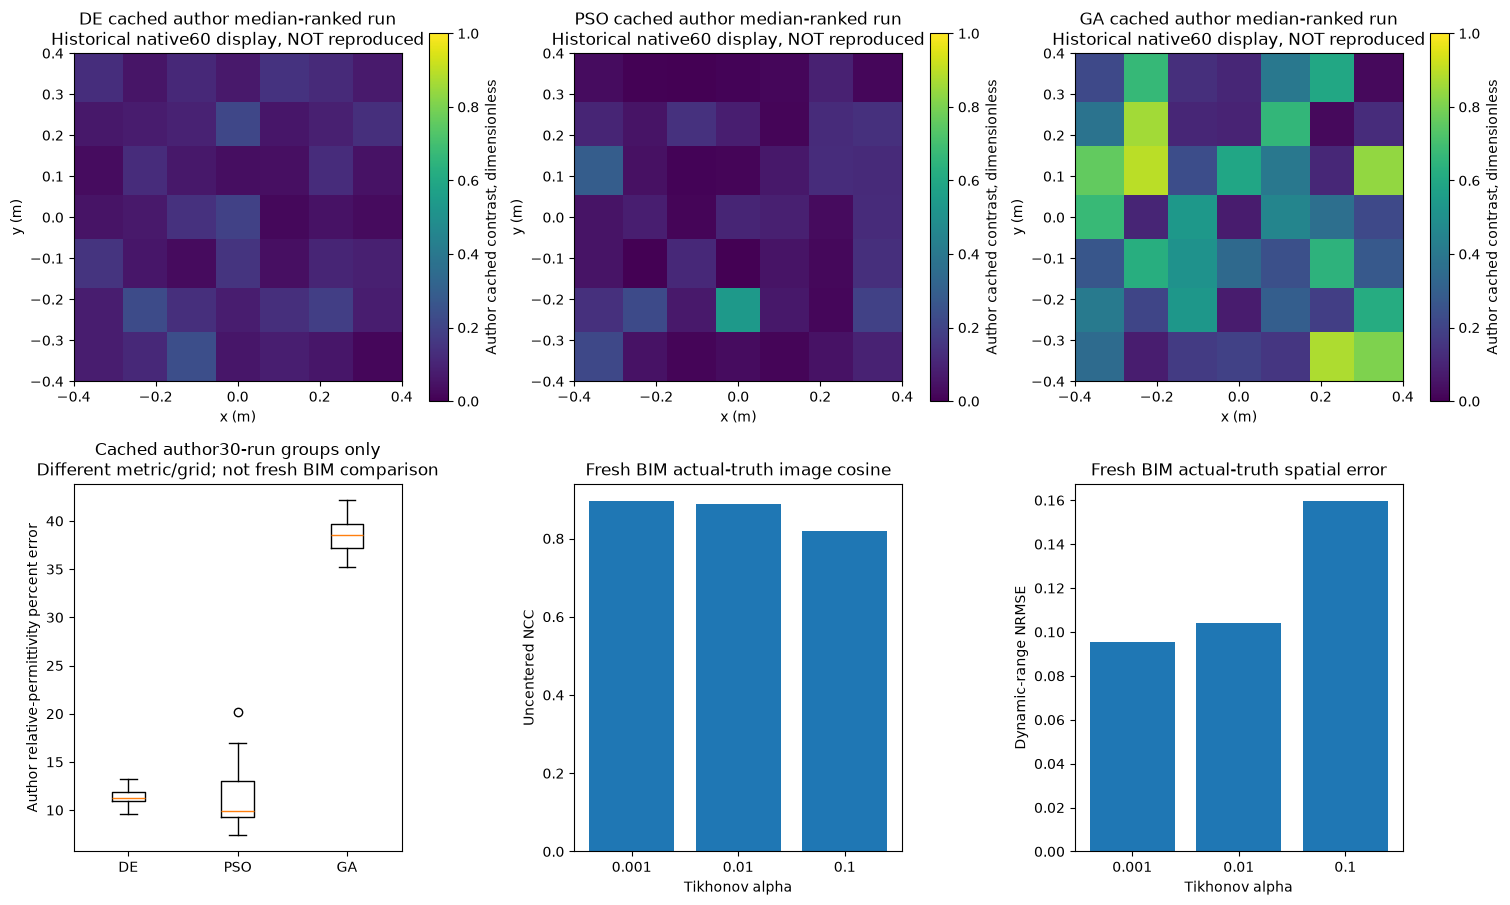

Explicit private review export completed.


In [3]:
figures=make_figures(data,experiments)
for figure in figures:
    display(figure)
    plt.close(figure)
export_directory=os.environ.get('IMAGING_REVIEW_EXPORT')
if export_directory:
    export(figures,experiments,Path(export_directory))
    print('Explicit private review export completed.')

## 6. Conclusion

### Interpretation and limits

The submitted native real contrast is evaluated against actual cell-mean simulation truth and a separately recomputed physical field. A consistent fit does not remove sparse-aperture spatial ambiguity or model/discretization error. Existing author noise is a1%-amplitude random-phase phasor, not newly sampled Gaussian noise; no exact component variance is invented. The coarse pulse model and original60-cell synthesis differ, so a nonzero observation residual is expected even for the actual cell-mean map. No real-data validation, anatomical claim or arbitrary-grid generalization is asserted. These results establish the selected bound benchmark, independent original parity and stated physical checks.
